# Customer Churn Prediction Lab: Decision Trees and Model Tuning

## Introduction

You are a data scientist for a telecommunications company that is concerned about customer churn. The company has collected data on various customer attributes and behaviors, including demographics, account information, and service usage patterns.

Your task is to build a decision tree model that can predict whether a customer is likely to churn (cancel their service) in the near future, enabling the company to proactively reach out to at-risk customers with retention offers.

### Recall as a Critical Metric for Churn Prediction

In the context of customer churn prediction, recall is particularly important for business reasons that directly affect the bottom line. Recall measures the proportion of actual churners that your model correctly identifies.

**Why Recall Matters More Than Precision for Churn:**

When predicting customer churn, the cost of a false negative (missing a churning customer) is typically much higher than the cost of a false positive (incorrectly flagging a loyal customer as at-risk).

**The business cost of missing a churner (false negative):**
- Complete loss of future revenue from that customer.
- Increased customer acquisition costs to replace them.
- Potential negative word-of-mouth effects.
- Lost opportunity to address their concerns and retain them.

**The business cost of incorrectly flagging a non-churner (false positive):**
- Resources spent on unnecessary retention efforts (e.g. discounts or outreach).
- Minor potential annoyance to the satisfied customer.

In most subscription businesses, acquiring a new customer costs 5-25 times more than retaining an existing one. This asymmetric cost structure makes missing a churning customer (low recall) much more expensive than incorrectly identifying a loyal customer as at-risk.

**Note: You are expected to use recall to score and evaluate your models.**

By the end of this lab, you will have:
1. Established a baseline decision tree model and evaluated its performance.
2. Performed hyperparameter tuning using randomized search.
3. Refined the model using grid search.
4. Evaluated final model performance.

### Part 0: Setup - Import Libraries and Load Data

First, import all the necessary libraries and load our dataset.

In [1]:
# CodeGrade step0

# Import required libraries:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report, recall_score, ConfusionMatrixDisplay

# Set random seed for reproducibility:
np.random.seed(42)

#### Loading and Exploring the Dataset

The dataset contains customer information and a target variable called `churn` indicating whether they cancelled their service (1) or not (0).

In [2]:
# CodeGrade step0

# Run this cell without changes:
# Load the dataset:
df_telco = pd.read_csv("telecom_churn_processed.csv")

In [3]:
# Run this cell without changes:
# Display basic information about the dataset:
df_telco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   account_age_months  20000 non-null  int64  
 1   monthly_charges     20000 non-null  float64
 2   subscription_tier   20000 non-null  int64  
 3   support_calls       20000 non-null  int64  
 4   reported_issues     20000 non-null  int64  
 5   inactive_days       20000 non-null  int64  
 6   usage_decline       20000 non-null  float64
 7   competitor_offer    20000 non-null  int64  
 8   promotion_response  20000 non-null  int64  
 9   contract_type       20000 non-null  int64  
 10  payment_method      20000 non-null  int64  
 11  online_security     20000 non-null  int64  
 12  tech_support        20000 non-null  int64  
 13  churn               20000 non-null  int64  
dtypes: float64(2), int64(12)
memory usage: 2.1 MB


In [4]:
# Run this cell without changes:
# Check the first few rows of the dataset:
df_telco.head()

,account_age_months,monthly_charges,subscription_tier,support_calls,reported_issues,inactive_days,usage_decline,competitor_offer,promotion_response,contract_type,payment_method,online_security,tech_support,churn
0,12,73.73,3,3,2,7,8.9,0,0,2,0,0,0,0
1,35,58.23,1,5,3,18,18.6,0,1,0,3,1,0,0
2,32,57.90,2,5,2,16,22.5,1,0,2,0,1,1,0
3,17,85.43,2,5,2,12,10.0,0,0,1,0,1,0,0
4,41,87.41,1,3,3,22,20.3,1,1,1,1,0,0,1


In [5]:
# Run this cell without changes:
# Check the distribution of the target variable:
df_telco["churn"].value_counts(normalize = True)

churn
0    0.6573
1    0.3427
Name: proportion, dtype: float64

### Part 1: Initial Model Assessment

Establish a baseline decision tree model using default parameters to understand how well a basic decision tree performs on our data.

#### Data Preparation

Prepare your data for modeling. For simplicity, we will assume the data is already preprocessed, but in a real scenario, you would need to handle missing values, encode categorical variables, etc.
- Use a 75/25 split.
- And set `random_state = 42` for both the split and the decision tree model.

In [6]:
# CodeGrade step1

# Define the features (X) and the target variable (y):
# Select all columns except `churn` as features:
X = df_telco.drop(columns = "churn")
# Use `churn` as the target variable:
y = df_telco["churn"]

# Split the dataset into training (75%) and testing (25%) sets, with
# `random_state = 42`:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, 
                                                    random_state = 42)

In [7]:
# CodeGrade step2

# Create a baseline decision tree classifier model with default parameters and
# `random_state = 42`:
baseline_model = DecisionTreeClassifier(random_state = 42)

# Perform cross-validation to get a robust estimate of model performance:
# Set `scoring = "recall"`:
# This should be a list of scores.
baseline_scores = cross_val_score(baseline_model, X_train, y_train, cv = 5, 
                                  scoring = "recall")

In [8]:
# CodeGrade step3

# Fit the baseline model to the training data to examine feature importance:
baseline_fit = baseline_model.fit(X_train, y_train)

# Get training predictions:
baseline_train_preds = baseline_fit.predict(X_train)

# Get the training recall score:
baseline_train_score = recall_score(y_train, baseline_train_preds)

# Create a dictionary of feature importances {feature_name : importance_value}:
initial_importance = dict(sorted(
                          zip(X.columns, baseline_fit.feature_importances_), 
                          key = lambda item: item[1], reverse = True))

In [9]:
# Run this cell without changes:
# Display CV and training scores:
print(f"Baseline model training recall: {baseline_train_score:.3f}")
print(f"Baseline model cross-validation recall: {baseline_scores.mean():.3f}")

# Display feature importances:
print("\nInitial Feature Importance:")
initial_importance

Baseline model training recall: 1.000
Baseline model cross-validation recall: 0.879

Initial Feature Importance:


{'monthly_charges': 0.2203411386435189,
 'subscription_tier': 0.21699174492783263,
 'usage_decline': 0.16336026504582968,
 'support_calls': 0.1540278089239634,
 'account_age_months': 0.08737058226600114,
 'competitor_offer': 0.07181179580258314,
 'reported_issues': 0.03531838461657587,
 'inactive_days': 0.02171966885196139,
 'payment_method': 0.008704718931263778,
 'contract_type': 0.0071163418943040084,
 'online_security': 0.005872612974407575,
 'promotion_response': 0.004619658633116299,
 'tech_support': 0.0027452784886419163}

#### Analyzing the Baseline Model

Now, let's reflect on what we've learned from the baseline model.
1. Is our model overfitting, underfitting, or balanced? How can you tell?

The baseline model is overfitting because it has a training recall score of 1.000, but a cross-validation recall score of only 0.879. That is still a pretty good cross-validation recall, but it is lower than the training recall, indicating that the baseline model does not generalize quite as well as it predicts on its training data.

2. Which features appear to be most important for predicting churn?

The features `monthly_charges`, `subscription_tier`, `usage_decline`, and `support_calls` appear to be most important for predicting churn. These four features alone account for about 75% of the baseline model's decision-making.

3. Based on your findings, what should be your focus in hyperparameter tuning?

The focus in hyperparameter tuning should be on reducing model complexity to reduce overfitting, as the model overfits the training data and there are some features that barely contribute to the decision tree's splits. We could decrease the `max_depth` of the tree or increase the `min_samples_leaf` to accomplish this.

### Part 2: Broad Exploration with Randomized Search

Use randomized search to efficiently explore a broad parameter space. This will help identify promising regions without evaluating every possible parameter combination. Include the following hyperparameters and distributions in your randomized search:
- `"criterion": ["gini", "entropy", "log_loss"]`
- `"max_depth": np.arange(3, 100, 2)`
- `"min_samples_split": np.arange(2, 21)`
- `"min_samples_leaf": np.arange(1, 21)`

In [10]:
# CodeGrade step4

# Define parameter distributions for random search:
param_dist = {"criterion": ["gini", "entropy", "log_loss"], 
              "max_depth": np.arange(3, 100, 2), 
              "min_samples_split": np.arange(2, 21), 
              "min_samples_leaf": np.arange(1, 21)}

In [11]:
# CodeGrade step5

# Create base model object with `random_state = 42`:
# This should be a DecisionTreeClassifier with `random_state = 42`, just like
# your baseline_model. The difference is that the model_search will vary its
# hyperparameters instead of relying on the defaults.
model_search = DecisionTreeClassifier(random_state = 42)

# Initialize the randomized search (ensure you are scoring based on recall):
random_search = RandomizedSearchCV(model_search, param_dist, n_iter = 100, cv = 
                                   5, scoring = "recall", random_state = 42)

# Perform the search (fit it to the data):
random_search.fit(X_train, y_train)

# Extract results from the random search:
best_parameters_rand = random_search.best_params_
bestcv_score_rand = random_search.best_score_
# Use the `.best_estimator_` attribute from the search:
best_training_preds_rand = random_search.best_estimator_.predict(X_train)
best_training_score_rand = recall_score(y_train, best_training_preds_rand)

In [12]:
# Run this cell without changes:
# Print the randomized search results:
print("Best parameters from random search:")
print(best_parameters_rand)
print(f"Best cross-validation score: {bestcv_score_rand:.3f}")
print(f"Best training score: {best_training_score_rand:.3f}")

Best parameters from random search:
{'min_samples_split': 16, 'min_samples_leaf': 9, 'max_depth': 95, 'criterion': 'log_loss'}
Best cross-validation score: 0.899
Best training score: 0.935


#### Analyzing the Randomized Search Results

1. How do the best parameters from the randomized search compare to the default parameters?

The randomized search selected `criterion = "log_loss"`, `max_depth = 95`, `min_samples_split = 16`, and `min_samples_leaf = 9`. Compared to the defaults, the selected model uses a different splitting criterion and requires more samples to split a node or create a leaf. Although the maximum depth is set to 95, the other parameters help restrict the tree's growth.

2. Has the model's performance improved? By how much?

The model's cross-validation recall has improved from 0.879 to 0.899, an improvement of 0.020, or 2.0 percentage points.

3. Is there still evidence of overfitting, and if so, has it been reduced?

There is still evidence of overfitting because the training recall of 0.935 is higher than the cross-validation recall of 0.899. However, overfitting has been reduced because the gap between the scores decreased from 0.121 for the baseline model to 0.036 after randomized search.

### Part 3: Focused Optimization with Grid Search

Based on the results from the randomized search, now perform a more focused grid search around the promising parameter regions identified.

NOTE: It is okay if your model does not improve or has similar performance, as this is often an iterative process, while you are only doing one grid search here.

In the previous step, you used `RandomizedSearchCV` to identify a strong set of hyperparameters for a decision tree classifier.

In this step, you will define a focused parameter grid that:
- Uses the best hyperparameters found in the random search as a starting point.
- Explores a small range of nearby values for the numeric parameters.
- Keeps the grid relatively small so that grid search runs efficiently.

Guidelines:
- Use the value of `criterion` found in `best_parameters_rand`.
- For numeric parameters (`max_depth`, `min_samples_split`, and `min_samples_leaf`):
    - Include the best value from the random search.
    - Include slightly smaller and slightly larger values around it.
- Ensure all parameter values remain valid for a decision tree (for example, minimum values should not be less than 1 or 2, as appropriate).
- Store your grid in a dictionary called `focused_param_grid`.

*Hint:*
Think about how you might create a list like `[best_value - small_amount, best_value, best_value + small_amount]` for each numeric parameter.

In [13]:
# CodeGrade step6

# Define a focused parameter grid based on the best parameters from the random
# search:
focused_param_grid = {"criterion": ["log_loss"], 
                      "max_depth": [93, 94, 95, 96, 97], 
                      "min_samples_split": [12, 14, 16, 18, 20], 
                      "min_samples_leaf": [5, 7, 9, 11, 13]}

In [14]:
# CodeGrade step7

# Initialize the grid search and make sure you are scoring based on recall:
# Let the cross-validation parameter be 3 (to reduce runtime).
# For parallelism, you can include `n_jobs = -1` as a grid search parameter.
grid_search = GridSearchCV(model_search, focused_param_grid, cv = 3, scoring = 
                           "recall", n_jobs = -1)

# Perform the grid search (fit it to the data):
grid_search.fit(X_train, y_train)

# Extract results from the grid search:
best_parameters_grid = grid_search.best_params_
bestcv_score_grid = grid_search.best_score_
# Use the `.best_estimator_` attribute from the search:
best_training_preds_grid = grid_search.best_estimator_.predict(X_train)
best_training_score_grid = recall_score(y_train, best_training_preds_grid)

In [15]:
# Run this cell without changes:
# Print the grid search results:
print("Best parameters from grid search:")
print(best_parameters_grid)
print(f"Best cross-validation score: {bestcv_score_grid:.3f}")
print(f"Best training score: {best_training_score_grid:.3f}")

Best parameters from grid search:
{'criterion': 'log_loss', 'max_depth': 93, 'min_samples_leaf': 7, 'min_samples_split': 12}
Best cross-validation score: 0.893
Best training score: 0.938


### Part 4: Final Validation

Evaluate your final tuned model on the held-out test set to get an unbiased estimate of its performance.

In [16]:
# CodeGrade step8

# Get the best model from your grid search:
final_model = grid_search.best_estimator_

# Get the best model's predictions on the test set:
y_pred = final_model.predict(X_test)

# Evaluate the best model's recall score on the test set:
final_test_score = recall_score(y_test, y_pred)

In [17]:
# Run this cell without changes:
# Print the final model results:
print("Final Model Evaluation:")
print(f"Best parameters: {grid_search.best_params_}")
print(f"Cross-validation recall: {bestcv_score_grid:.3f}")
print(f"Test set recall: {final_test_score:.3f}")

Final Model Evaluation:
Best parameters: {'criterion': 'log_loss', 'max_depth': 93, 'min_samples_leaf': 7, 'min_samples_split': 12}
Cross-validation recall: 0.893
Test set recall: 0.892


In [18]:
# CodeGrade step9

# Calculate the confusion matrix for the final model's predictions on the
# testing data:
cm = confusion_matrix(y_test, y_pred)

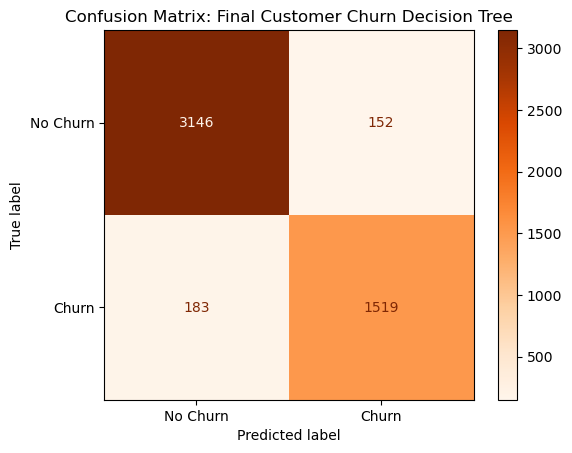

In [19]:
# Run this cell without changes:
# Plot the confusion matrix:
disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = ["No Churn", "Churn"])
disp.plot(cmap = "Oranges", values_format = "d")
plt.title("Confusion Matrix: Final Customer Churn Decision Tree")
plt.show()

In [20]:
# CodeGrade step10

# Extract the feature importance for the final model and create a dicitonary
# for it:
final_feature_importance = dict(sorted(
                                zip(X.columns, final_model.feature_importances_), 
                                key = lambda item: item[1], reverse = True))
final_feature_importance

{'monthly_charges': 0.21902818765964333,
 'usage_decline': 0.19782271031097542,
 'competitor_offer': 0.19136539146428755,
 'subscription_tier': 0.1264040180863381,
 'support_calls': 0.10925115182056182,
 'account_age_months': 0.0803653647011588,
 'reported_issues': 0.04709037867521238,
 'inactive_days': 0.013310768680863123,
 'payment_method': 0.004847406056687785,
 'contract_type': 0.0034031272932716333,
 'promotion_response': 0.003187622323202342,
 'tech_support': 0.002776416584697492,
 'online_security': 0.0011474563431001254}

## Personalized Lab Recap (Not Part of the Assignment): Customer Churn Prediction with Decision Trees

### What I Did

In this lab, I built a decision tree model to predict whether a customer would leave (churn) or stay with a subscription company. The goal was to identify as many customers who actually churn as possible, so **recall** was used as our main evaluation metric.

I started with a baseline decision tree, then used randomized search and grid search to find better hyperparameters. Finally, I evaluated the tuned model on a separate test set that had not been used to train or tune the model.

### Comparing the Different Models

| Model | Cross-Validation Recall | Training Recall | Training-CV Gap |
|---|---:|---:|---:|
| Baseline model | 0.879 | 1.000 | 0.121 |
| Randomized search | 0.899 | 0.935 | 0.036 |
| Grid search (final model) | 0.893 | 0.938 | 0.045 |

The baseline model had perfect recall on its training data, but its cross-validation recall was lower. This was evidence of **overfitting**: the model performed extremely well on the data it learned from, but not quite as well on other data.

Randomized search improved cross-validation recall to 0.899 and reduced the difference between training and cross-validation recall. Grid search had slightly lower cross-validation recall (0.893), so the randomized-search model performed a little better on that measure. However, both tuned models improved on the baseline's cross-validation recall.

### The Final Model

The grid search selected these hyperparameters:
- `criterion = "log_loss"`
- `max_depth = 93`
- `min_samples_split = 12`
- `min_samples_leaf = 7`

These settings control how the decision tree makes splits and how complex it is allowed to become. The minimum sample settings help restrict tree growth and can reduce overfitting. The selected values were the best combination among the options tested, not necessarily the best possible values overall.

### Final Model Test Results

- **Cross-validation recall:** 0.893 (89.3%)
- **Test-set recall:** 0.892 (89.2%)

These scores are almost identical, which is a good sign! The final model correctly identified about 89% of the customers who actually churned in the held-out test set. Its test performance was very close to what cross-validation had predicted.

I also plotted a confusion matrix to see how many predictions were correct and how many were mistakes. In particular, false negatives are customers who actually churned but whom the model predicted would stay.

### Which Features Mattered Most?

The five most important features in the final decision tree were:
1. `monthly_charges`
2. `usage_decline`
3. `competitor_offer`
4. `subscription_tier`
5. `support_calls`

These features accounted for about 75% of the model's total feature importance. This tells us which features the tree relied on most when making its predictions, but it does not prove that they cause customers to churn.

### The Main Takeaway

The most important lesson from this lab is that **a model that performs perfectly on its training data is not necessarily the best model**. I used cross-validation to compare models and tune their hyperparameters, then used a separate test set to estimate how well the final model generalizes to unseen data.

Machine learning is an iterative process: first you try a model, then you evaluate it, you adjust its settings, and then you compare the results to find a model that performs well beyond the data it was trained on.